# 01 · Exploração da base

Primeiro olhar sobre a base consolidada de teses e dissertações de Computação (2010–2024),
gerada por `src/build_dataset.py`. O objetivo aqui é entender o volume de trabalhos ao longo
do tempo, por grau e por região, e conferir a qualidade dos resumos antes da análise de texto.

In [6]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

sys.path.append("../src")
from preprocess import detectar_idioma, taxa_repeticao, chave_texto, LIMITE_REPETICAO

BASE = Path("../data/processed/teses_computacao_2010_2024.csv.gz")
FIGURAS = Path("../reports/figures")
FIGURAS.mkdir(parents=True, exist_ok=True)

# Cores fixas por grau, para o mesmo grau ter sempre a mesma cor em todos os gráficos
CORES = {"Mestrado": "#2a78d6", "Doutorado": "#eb6834", "Mestrado Profissional": "#1baf7a"}
TINTA = "#52514e"

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": TINTA,
    "xtick.color": TINTA,
    "ytick.color": TINTA,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#e8e7e3",
    "font.size": 10,
})

df = pd.read_csv(BASE)
total = f"{len(df):,}".replace(",", ".")
print(f"{total} trabalhos, de {df['ano'].min()} a {df['ano'].max()}")
df.head(3)

23.749 trabalhos, de 2010 a 2024


,ano,regiao,uf,ies_sigla,ies_nome,programa,area_conhecimento,titulo,grau,palavras_chave,resumo
0,2010,Norte,AM,UFAM,Universidade Federal do Amazonas,INFORMÁTICA,CIÊNCIA DA COMPUTAÇÃO,Uma Abordagem de Fusão de Dados em Redes de S...,Mestrado,"Fusão de dados, rastreamento de alvos","Em Redes de Sensores Sem Fio (RSSFs), algoritm..."
1,2010,Norte,AM,UFAM,Universidade Federal do Amazonas,INFORMÁTICA,CIÊNCIA DA COMPUTAÇÃO,Aplicação de Métodos de Fusão de Dados para D...,Mestrado,"Detecção de Eventos, Fusão de Dados",Aplicações propostas para detecção de eventos ...
2,2010,Norte,AM,UFAM,Universidade Federal do Amazonas,INFORMÁTICA,CIÊNCIA DA COMPUTAÇÃO,Um Método Probabilístico para Preenchimento A...,Mestrado,"Extração de dados, Banco de Dados",A solução mais comum atualmente para usuários ...


## Volume por ano e por grau

In [7]:
por_grau = df.groupby(["ano", "grau"]).size().unstack(fill_value=0)
por_grau

grau,Doutorado,Doutorado Profissional,Mestrado,Mestrado Profissional
ano,,,,
2010,149,0,928,69
2011,127,0,978,61
2012,202,0,1121,46
2013,208,0,1205,128
2014,242,0,1221,80
2015,305,0,1246,134
2016,331,0,1338,138
2017,413,0,1253,243
2018,352,0,1292,136


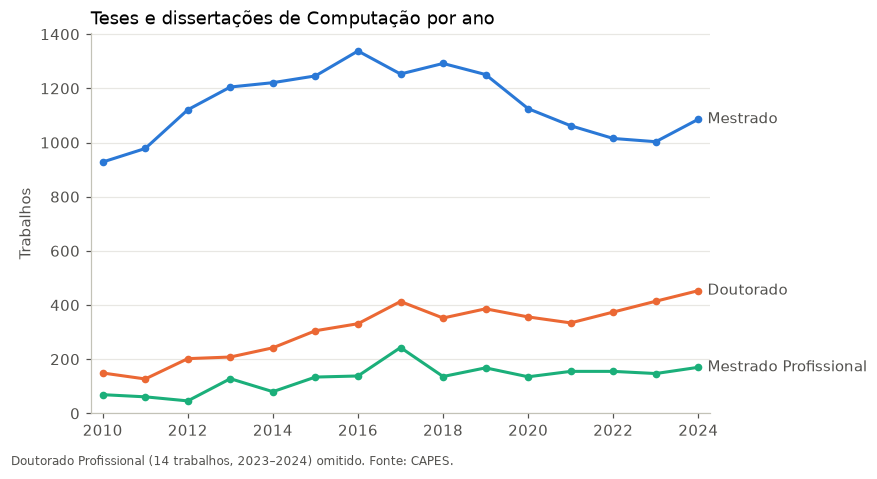

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.2))
for grau, cor in CORES.items():
    serie = por_grau[grau]
    ax.plot(serie.index, serie.values, color=cor, linewidth=2, marker="o", markersize=4)
    ax.annotate(grau, (serie.index[-1], serie.values[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", color=TINTA)

ax.set_title("Teses e dissertações de Computação por ano", loc="left", fontsize=12)
ax.set_ylabel("Trabalhos")
ax.set_xticks(por_grau.index[::2])
ax.set_ylim(0)
ax.margins(x=0.02)
fig.text(0.01, -0.02, "Doutorado Profissional (14 trabalhos, 2023–2024) omitido. Fonte: CAPES.",
         color=TINTA, fontsize=8)
fig.tight_layout()
fig.savefig(FIGURAS / "trabalhos_por_ano_grau.png", bbox_inches="tight")

O mestrado acadêmico domina o volume, mas atingiu o pico em 2016 e caiu até 2023. O doutorado
cresce de forma quase contínua no período. Para ver isso melhor, vale olhar a **participação** do
doutorado no total de trabalhos de cada ano.

ano,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
% doutorado,13.0,10.9,14.8,13.5,15.7,18.1,18.3,21.6,19.8,21.4,22.0,21.5,24.2,26.4,26.4


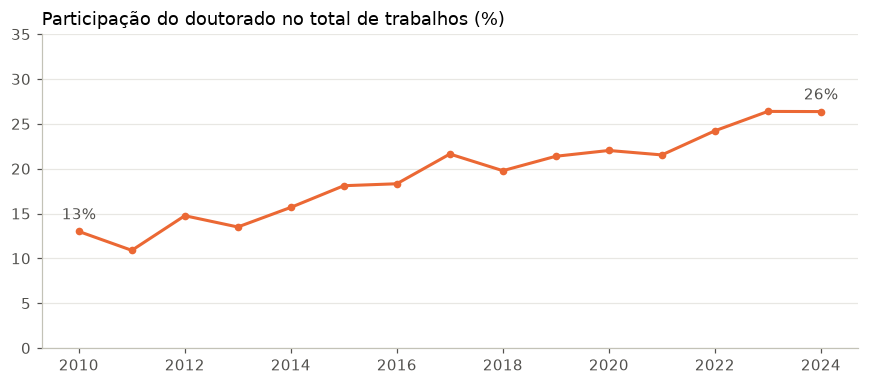

In [9]:
participacao = (por_grau["Doutorado"] / por_grau.sum(axis=1) * 100)

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(participacao.index, participacao.values, color=CORES["Doutorado"], linewidth=2,
        marker="o", markersize=4)
for ano in (participacao.index[0], participacao.index[-1]):
    ax.annotate(f"{participacao[ano]:.0f}%", (ano, participacao[ano]), xytext=(0, 8),
                textcoords="offset points", ha="center", color=TINTA)

ax.set_title("Participação do doutorado no total de trabalhos (%)", loc="left", fontsize=12)
ax.set_xticks(participacao.index[::2])
ax.set_ylim(0, 35)
fig.tight_layout()
fig.savefig(FIGURAS / "participacao_doutorado.png", bbox_inches="tight")
participacao.round(1).to_frame("% doutorado").T

## Distribuição por região e instituição

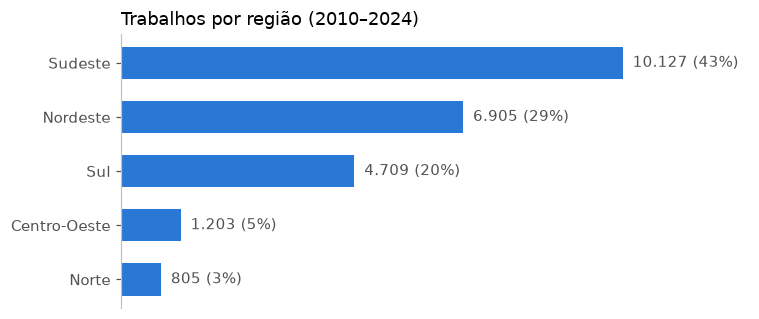

In [10]:
por_regiao = df["regiao"].value_counts().sort_values()
pct = por_regiao / por_regiao.sum() * 100

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(por_regiao.index, por_regiao.values, color="#2a78d6", height=0.6)
for i, (n, p) in enumerate(zip(por_regiao.values, pct.values)):
    ax.text(n, i, f"  {n:,} ({p:.0f}%)".replace(",", "."), va="center", color=TINTA)
ax.set_title("Trabalhos por região (2010–2024)", loc="left", fontsize=12)
ax.grid(False)
ax.set_xticks([])
ax.spines["bottom"].set_visible(False)
ax.set_xlim(0, por_regiao.max() * 1.25)
fig.tight_layout()
fig.savefig(FIGURAS / "trabalhos_por_regiao.png", bbox_inches="tight")

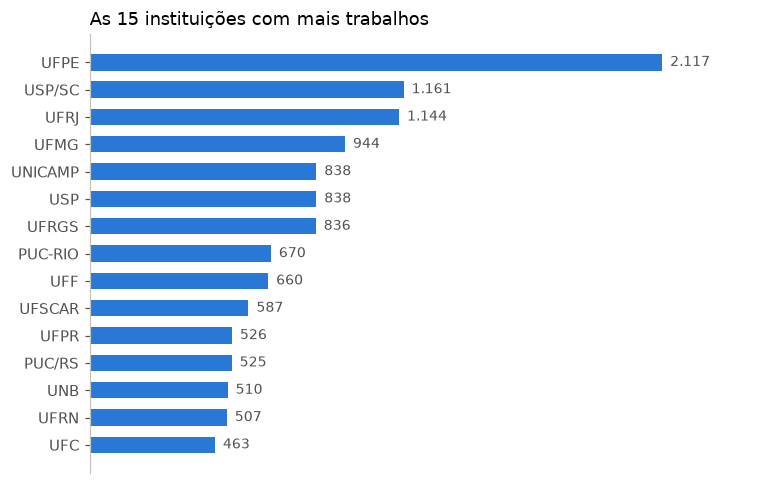

In [11]:
top_ies = df["ies_sigla"].value_counts().head(15).sort_values()

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(top_ies.index, top_ies.values, color="#2a78d6", height=0.6)
for i, n in enumerate(top_ies.values):
    ax.text(n, i, f"  {n:,}".replace(",", "."), va="center", color=TINTA, fontsize=9)
ax.set_title("As 15 instituições com mais trabalhos", loc="left", fontsize=12)
ax.grid(False)
ax.set_xticks([])
ax.spines["bottom"].set_visible(False)
ax.set_xlim(0, top_ies.max() * 1.15)
fig.tight_layout()
fig.savefig(FIGURAS / "top_instituicoes.png", bbox_inches="tight")

O Sudeste concentra mais de 40% da produção, e o Nordeste aparece em segundo, puxado pela
UFPE, a instituição com mais trabalhos no período. Norte e Centro-Oeste somam menos de 10%.

## Qualidade dos resumos

Antes da análise de texto, três problemas apareceram ao ler amostras dos resumos:

- **Caixa alta:** a partir de 2013, a CAPES publica os resumos todos em maiúsculas. Para a
  análise de texto, tudo será convertido para minúsculas.
- **Resumos em inglês:** alguns trabalhos têm o abstract no campo do resumo.
- **Resumos corrompidos ou duplicados:** trechos repetidos várias vezes no mesmo resumo, ou o
  mesmo resumo cadastrado em trabalhos diferentes.

In [12]:
letras = df["resumo"].str.count(r"[A-Za-zÀ-ÿ]")
maiusculas = df["resumo"].str.count(r"[A-ZÀ-Þ]")
em_caixa_alta = (maiusculas / letras) > 0.8
em_caixa_alta.groupby(df["ano"]).mean().mul(100).round(0).to_frame("% em caixa alta").T

ano,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
% em caixa alta,0.0,0.0,0.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0


In [13]:
qualidade = pd.DataFrame({
    "em inglês": df["resumo"].map(detectar_idioma) == "en",
    "corrompido": df["resumo"].map(taxa_repeticao) > LIMITE_REPETICAO,
    "duplicado": df["resumo"].map(chave_texto).duplicated(keep=False),
})
resumo_qualidade = qualidade.sum().to_frame("trabalhos")
resumo_qualidade["% da base"] = (resumo_qualidade["trabalhos"] / len(df) * 100).round(1)
resumo_qualidade

,trabalhos,% da base
em inglês,625,2.6
corrompido,23,0.1
duplicado,99,0.4


In [14]:
# Exemplo de resumo corrompido: o mesmo trecho repetido várias vezes
repeticao = df["resumo"].map(taxa_repeticao)
exemplo = df.loc[repeticao.idxmax(), "resumo"]
exemplo[:400] + " ..." 


'RESOLUÇÃO DE CORREFERÊNCIAS É UM PROCESSO QUE CONSISTE EM IDENTIFICAR AS DIVERSAS FORMAS UMA RESOLUÇÃO DE CORREFERÊNCIAS É UM PROCESSO QUE CONSISTE EM IDENTIFICAR AS DIVERSAS FORMAS UMA RESOLUÇÃO DE CORREFERÊNCIAS É UM PROCESSO QUE CONSISTE EM IDENTIFICAR AS DIVERSAS FORMAS UMA RESOLUÇÃO DE CORREFERÊNCIAS É UM PROCESSO QUE CONSISTE EM IDENTIFICAR AS DIVERSAS FORMAS UMA RESOLUÇÃO DE CORREFERÊNCIAS  ...'

Juntos, esses casos somam cerca de 3% da base (alguns trabalhos têm mais de um problema). Eles continuam na base consolidada (servem
para as contagens por ano, grau e região), mas ficam **fora da análise de texto**. Essa
marcação é feita em `src/preprocess.py`.

In [15]:
tamanho = df["resumo"].str.split().str.len()
tamanho.describe().round(0).to_frame("palavras por resumo").T

,count,mean,std,min,25%,50%,75%,max
palavras por resumo,23749.0,267.0,107.0,1.0,196.0,257.0,325.0,4691.0


Um resumo típico tem perto de 250 palavras, que é tamanho adequado tanto para modelos de tópicos quanto para um LLM.